<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/seminar_note_1_2_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Evaluation

## 어떤 모델이 좋은 모델인가?

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
import warnings
warnings.filterwarnings(action='ignore')

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import pandas as pd
import numpy as np

## Confusion matrix with recall & precision

In [3]:
y_true = ['pos', 'pos','pos','pos','pos','pos','pos','pos','pos','pos','pos','pos',
         'neg', 'neg','neg','neg','neg','neg','neg','neg','neg','neg']
y_pred = ['pos', 'pos','pos','pos','pos','neg','neg','neg','neg','neg','neg','neg',
         'neg', 'neg','neg','neg','neg','neg','neg','pos','pos','pos']

In [4]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_true, y_pred)

array([[7, 3],
       [7, 5]])

<Axes: >

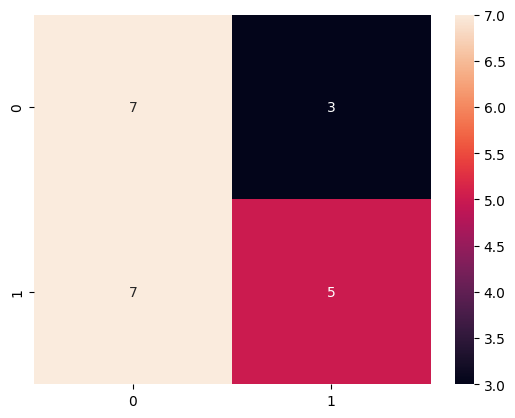

In [5]:
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True)

In [6]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
(tn, fp, fn, tp)

(np.int64(7), np.int64(3), np.int64(7), np.int64(5))

https://en.wikipedia.org/wiki/Precision_and_recall
<img src='https://thumb.wikimedia.org/wikipedia/commons/thumb/2/26/Precisionrecall.svg/960px-Precisionrecall.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail'>

In [7]:
from sklearn.metrics import classification_report
target_names = ['class 0(negative)', 'class 1(positive)']
print(classification_report(y_true, y_pred, target_names=target_names))

                   precision    recall  f1-score   support

class 0(negative)       0.50      0.70      0.58        10
class 1(positive)       0.62      0.42      0.50        12

         accuracy                           0.55        22
        macro avg       0.56      0.56      0.54        22
     weighted avg       0.57      0.55      0.54        22



# Import the dataset Wisconsin breast cancer dataset from skelarn.

In [8]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
cancer = pd.DataFrame(np.c_[cancer['target'], cancer['data']],
                      columns = np.append('target', cancer['feature_names']))
cancer['target'] = cancer['target'].map({0.0: 1, 1.0:0}).astype('int64')
cancer.shape
cancer.head()
cancer.target.value_counts(normalize=True) #cancer.target.value_counts().plot(kind='bar', rot='360')

(569, 31)

,target,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,proportion
target,
0,0.627417
1,0.372583


#### 층화 추출

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

In [10]:
# Separate the independent variables from the dependent variable.
X = cancer.drop('target', axis = 1)
y = cancer['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)
clf = SVC(random_state=0, probability=True)
clf.fit(X_train, y_train)

SVC(probability=True, random_state=0)

## confusion_matrix

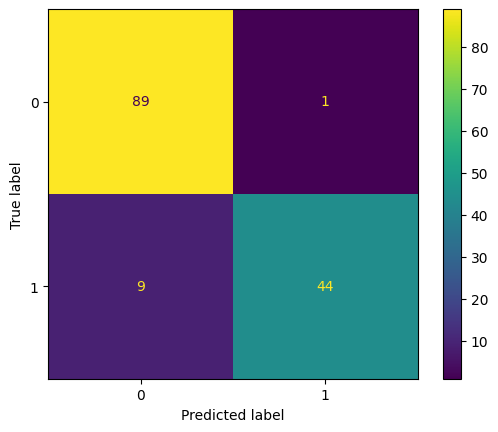

array([[89,  1],
       [ 9, 44]])

<Axes: >

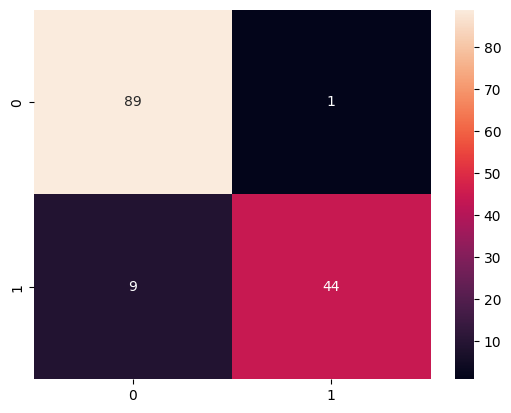

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ConfusionMatrixDisplay를 사용하여 시각화
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test)
plt.show()

y_pred = clf.predict(X_test)
confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")

### classification_report

In [12]:
from sklearn.metrics import classification_report
target_names = ['생존(0)', '사망(1)']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

       생존(0)       0.91      0.99      0.95        90
       사망(1)       0.98      0.83      0.90        53

    accuracy                           0.93       143
   macro avg       0.94      0.91      0.92       143
weighted avg       0.93      0.93      0.93       143



### 예측 모형의 성능지표 이해하기

- **허위** 음성과 **허위** 양성은 **잘못** 분류
- **실제** 음성과 **실제** 양성은 **올바로** 분류
- **정확도**는 올바로 분류된 비율

> $\frac{\text{true samples}}{\text{total samples}}$

- **정밀도**는 올바르게 분류된 **예측** 양성의 비율

> $\frac{\text{true positives}}{\text{true positives + false positives}}$

- **재현율**은 올바르게 분류된 **실제** 양성의 비율

> $\frac{\text{true positives}}{\text{true positives + false negatives}}$

- **AUC**는 ROC-AUC(Area Under the Curve of a Receiver Operating Characteristic) 곡선을 의미.
- **AUPRC**는 PR curve AUC를 의미. 이 메트릭은 다양한 확률 임계값에 대한 정밀도-재현율 pair

### manual calculation

In [13]:
cm = confusion_matrix(y_test, y_pred)
print(f'정확도(accuracy): {(cm * np.eye(2)).sum() / cm.sum():.3f}')
print(f'정밀도(precision): {((cm * np.eye(2)).sum(axis=0) / cm.sum(axis=0)).round(3)}')
precision = (cm * np.eye(2)).sum(axis=0) / cm.sum(axis=0)
print(f'검측율(recall): {((cm * np.eye(2)).sum(axis=1) / cm.sum(axis=1)).round(3)}')
recall = (cm * np.eye(2)).sum(axis=1) / cm.sum(axis=1)
print(f'f1-score(Harmonic mean): {((2 / (1 / precision + 1 / recall))).round(3)}')

정확도(accuracy): 0.930
정밀도(precision): [0.908 0.978]
검측율(recall): [0.989 0.83 ]
f1-score(Harmonic mean): [0.947 0.898]


In [14]:
# 0일 확률, 1일 확률
y_probas = clf.predict_proba(X_test)
y_probas[0:10]
n = len(y_probas)
threshhold = np.linspace(0,1,n)
y_pred = y_probas[:,1].reshape(-1,1) > threshhold.reshape(1,-1)
y_pred.shape

array([[3.76796579e-06, 9.99996232e-01],
       [8.85468732e-01, 1.14531268e-01],
       [8.63579569e-01, 1.36420431e-01],
       [8.93773390e-01, 1.06226610e-01],
       [7.90447446e-01, 2.09552554e-01],
       [9.76891709e-01, 2.31082913e-02],
       [9.81544705e-01, 1.84552947e-02],
       [9.78905823e-01, 2.10941772e-02],
       [9.68385682e-01, 3.16143178e-02],
       [2.61464867e-01, 7.38535133e-01]])

(143, 143)

In [15]:
y_pred
y_pred.astype('int')

array([[ True,  True,  True, ...,  True,  True, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]], shape=(143, 143))

array([[1, 1, 1, ..., 1, 1, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       ...,
       [1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0]], shape=(143, 143))

In [16]:
y_pred[:, 0]
y_pred[:, 142]

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

              precision    recall  f1-score   support

       생존(0)       1.00      0.43      0.60        90
       사망(1)       0.51      1.00      0.68        53

    accuracy                           0.64       143
   macro avg       0.75      0.72      0.64       143
weighted avg       0.82      0.64      0.63       143



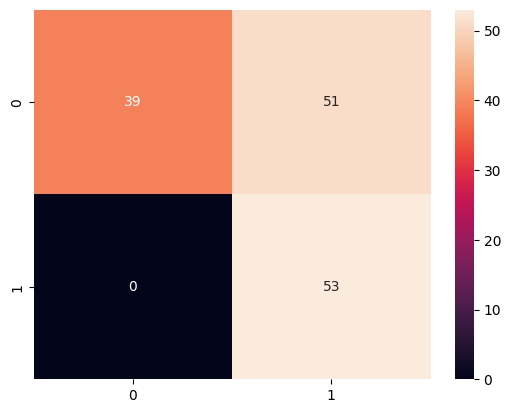

****************************************************************************************************
              precision    recall  f1-score   support

       생존(0)       0.83      1.00      0.91        90
       사망(1)       1.00      0.66      0.80        53

    accuracy                           0.87       143
   macro avg       0.92      0.83      0.85       143
weighted avg       0.90      0.87      0.87       143



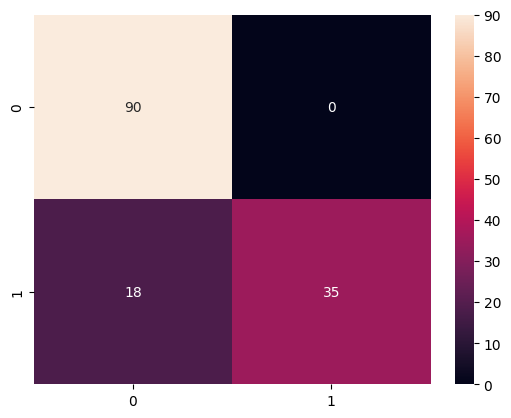

****************************************************************************************************


In [17]:
def threshhold_matrix(y_test, y_pred):
    target_names = ['생존(0)', '사망(1)']
    cm = confusion_matrix(y_test, y_pred)
    print(classification_report(y_test, y_pred, target_names=target_names))
    sns.heatmap(cm, annot = True, fmt="d"); plt.show()
    print('*'*100)

threshhold_matrix(y_test, y_pred[:,4])
threshhold_matrix(y_test, y_pred[:,140])

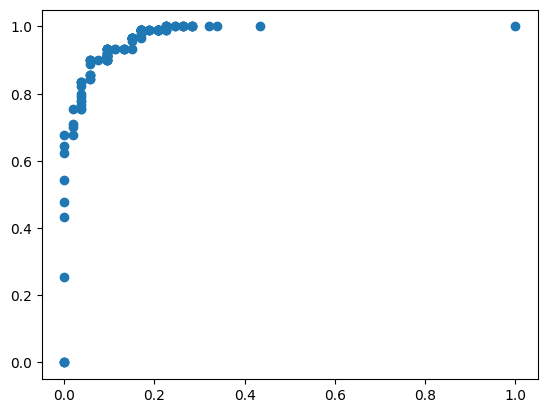

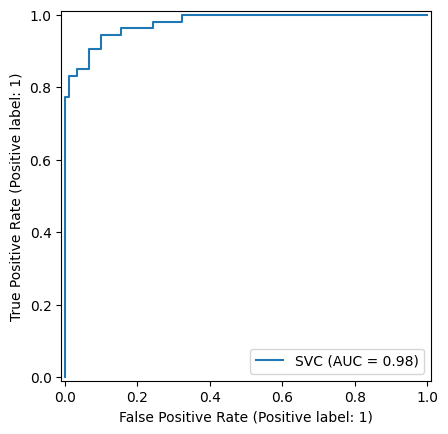

In [18]:
tpr = []; fpr = []
for i in range(n):
    cm = confusion_matrix(y_test, y_pred[:,i])
    tpr.append(cm[0,0]/cm.sum(axis=1)[0])
    fpr.append(cm[1,0]/cm.sum(axis=1)[1])
plt.scatter(fpr, tpr); plt.show()

from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.show()

In [19]:
((clf.predict_proba(X_test)[:,1] >= 0.3) == y_test).mean()
((clf.predict_proba(X_test)[:,1] >= 0.5) == y_test).mean()
((clf.predict_proba(X_test)[:,1] >= 0.8) == y_test).mean()

np.float64(0.9090909090909091)

np.float64(0.9230769230769231)

np.float64(0.916083916083916)

### roc_auc_score
#### roc 아래의 면적 / 넓으면(1에 가까우면) 좋음

In [20]:
from sklearn.metrics import roc_auc_score
y_score = clf.predict_proba(X_test)[:, 1]
roc_auc_score(y_test, y_score)

np.float64(0.9775681341719078)

### precision_recall_curve
#### th 변화에 따른 두 값의 변화

### average_precision_score

In [21]:
from sklearn.metrics import average_precision_score
average_precision = average_precision_score(y_test, y_score)
print(f'Average precision-recall score: {average_precision:0.2f}')

Average precision-recall score: 0.97


Text(0.5, 1.0, '2-class Precision-Recall curve: AP=0.97')

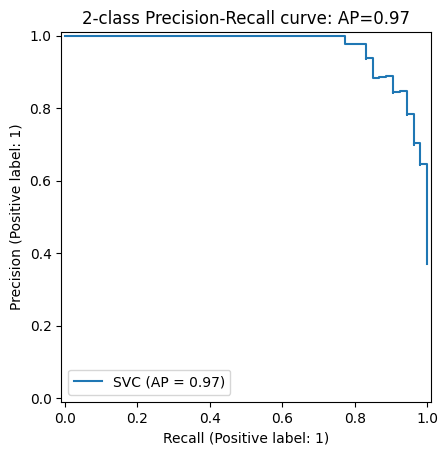

In [22]:
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score
disp = PrecisionRecallDisplay.from_estimator(clf, X_test, y_test)
disp.ax_.set_title(f'2-class Precision-Recall curve: AP={average_precision:0.2f}')

In [23]:
from sklearn.metrics import precision_recall_curve

def to_labels(pos_probs, threshold):
    return (pos_probs >= threshold).astype('int')

precisions, recalls, thresholds = precision_recall_curve(y_test, y_probas[:, 1])
scores = [np.sum(to_labels(y_probas[:, 1], t))/len(y_probas[:, 1]) for t in thresholds]

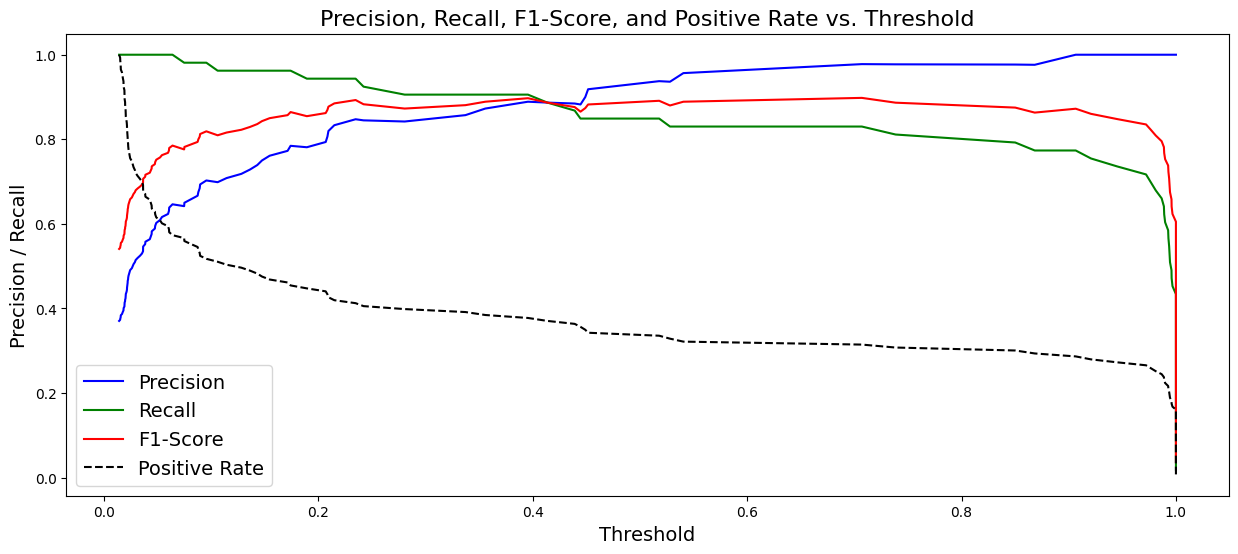

In [24]:
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds, scores):
    plt.rcParams["figure.figsize"] = (15, 6)
    plt.title('Precision, Recall, F1-Score, and Positive Rate vs. Threshold', fontsize=16)
    plt.plot(thresholds, precisions[:-1], 'b-', label='Precision')
    plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
    plt.plot(thresholds, (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1]),
             'r-', label='F1-Score')
    plt.plot(thresholds, scores, 'k--', label='Positive Rate')
    plt.ylabel('Precision / Recall', fontsize=14)
    plt.xlabel('Threshold', fontsize=14)
    plt.legend(loc='best', fontsize=14)

plot_precision_recall_vs_threshold(precisions, recalls, thresholds, scores)

## f1-score가 최대인 threshold?

In [25]:
from sklearn.metrics import f1_score
scores = [f1_score(y_test, to_labels(y_probas[:, 1], t)) for t in thresholds]
ix = np.argmax(scores)
print(f'Threshold(분류임계값)={thresholds[ix]:.3f}, at Maximum F-measure={scores[ix]:.3f}')

Threshold(분류임계값)=0.707, at Maximum F-measure=0.898


### plot_lift_curve / plot_cumulative_gain
- lift: the ratio between the results obtained with and without the predictive model
- cumulative_gain: percentage of the overall number of cases in a given category "gained" by targeting a percentage of the total number of cases

In [26]:
plt.rcParams["figure.figsize"] = (4,4)

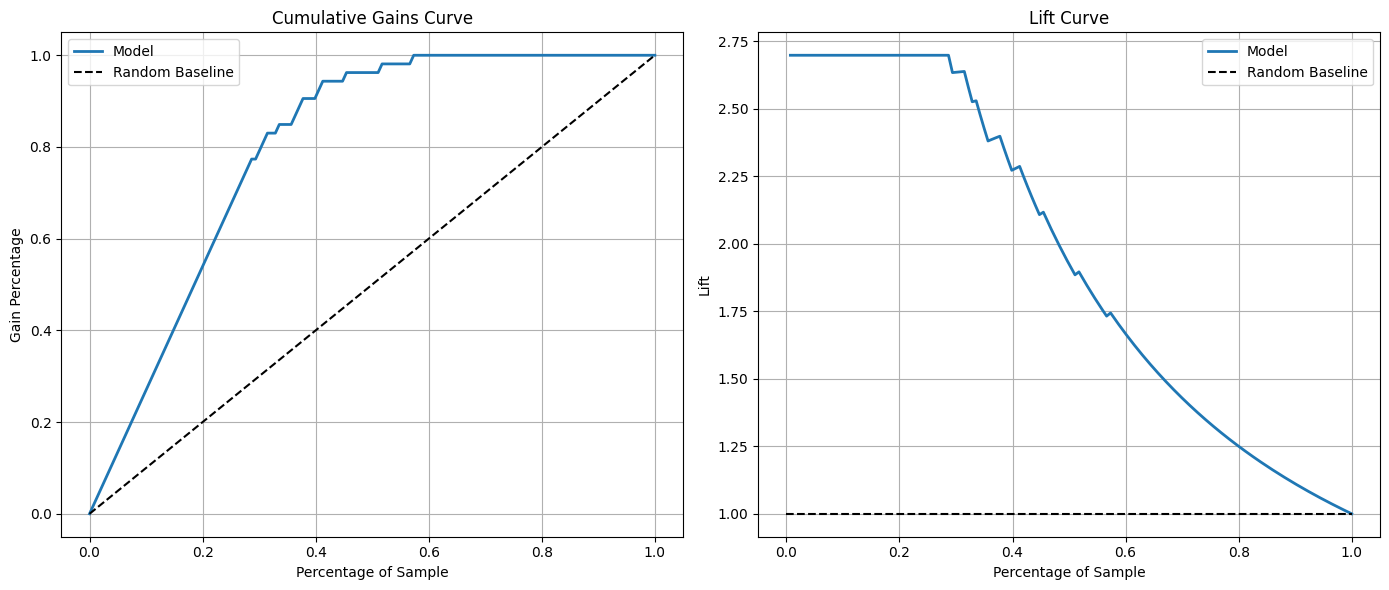

In [27]:
import matplotlib.pyplot as plt
import numpy as np

def plot_cumulative_gain_and_lift(y_test, y_probas):
    y_true = np.asarray(y_test)[np.argsort(y_probas[:, 1])[::-1]]
    gains = np.append(0, np.cumsum(y_true) / np.sum(y_true))
    pcts = np.linspace(0, 1, len(y_true) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    configs = [
        (ax1, pcts, gains, [0, 1], 'Cumulative Gains Curve', 'Gain Percentage'),
        (ax2, pcts[1:], gains[1:] / pcts[1:], [1, 1], 'Lift Curve', 'Lift')
    ]

    for ax, x, y, baseline, title, ylab in configs:
        ax.plot(x, y, lw=2, label='Model')
        ax.plot([0, 1], baseline, 'k--', label='Random Baseline')
        ax.set(title=title, xlabel='Percentage of Sample', ylabel=ylab)
        ax.legend(loc='best')
        ax.grid(True)

    plt.tight_layout()
    plt.show()

# 실행 예시
plot_cumulative_gain_and_lift(y_test, y_probas)

## 1.1.3. Probalistic Metrics

### brier_score_loss
#### mean square error 값과 동일

In [28]:
from sklearn.metrics import brier_score_loss
brier_score_loss(y_test, y_score)
brier_score_loss(y_test, y_probas[:, 1])

np.float64(0.05393556118435772)

np.float64(0.05393556118435772)

### log_loss
- Log Loss is the negative average of the log of corrected predicted probabilities for each instance
- 예측된 확률과 실제값의 차이의 log 값은 1에 가까울 수록 0에 근접

### Log Loss (로그 손실)

이진 분류 모델의 예측 확률과 실제 정답 사이의 차이를 측정한다.

$$
LogLoss = -\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
$$

- $N$: 전체 데이터 개수
- $y_i$: 실제 정답 (0 또는 1)
- $p_i$: 양성 클래스(1)에 대한 예측 확률
- $\log$: 자연로그 (Natural Logarithm)

**특징**
- Log Loss가 작을수록 좋은 모델이다.
- 정답에 높은 확률을 부여하면 손실이 작아진다.
- 틀린 정답에 높은 확률을 부여하면 손실이 크게 증가한다.

In [29]:
from sklearn.metrics import log_loss
log_loss(y_test, y_probas)

0.17809166281948552

### matthews_corrcoef
<img src="https://wikimedia.org/api/rest_v1/media/math/render/svg/33f3d62224f97cdef8bc559ee455c3f4815f5788">

- MCC is defined identically to Pearson's phi coefficient
- unbalanced 상황에서 잘 맞음

In [30]:
from sklearn.metrics import matthews_corrcoef
y_pred = clf.predict(X_test)
matthews_corrcoef(y_test, y_pred)

np.float64(0.8518535291230603)

### cohen_kappa_score
- Cohen's kappa measures the agreement between two raters
<img src="https://wikimedia.org/api/rest_v1/media/math/render/svg/1a7a8f738ea187a60443bac93cd53b4d9d6b2231">

In [31]:
from sklearn.metrics import cohen_kappa_score
# y_pred를 1차원 클래스 예측값으로 다시 올바르게 정의합니다.
y_pred = clf.predict(X_test)
cohen_kappa_score(y_test, y_pred)

np.float64(0.8453050627434011)

## Calibration plot

<Figure size 1500x800 with 0 Axes>

GaussianNB()

SVC(probability=True)

RandomForestClassifier()

Text(0.5, 0, 'Mean Predicted Probability')

Text(0, 0.5, 'Fraction of Positives')

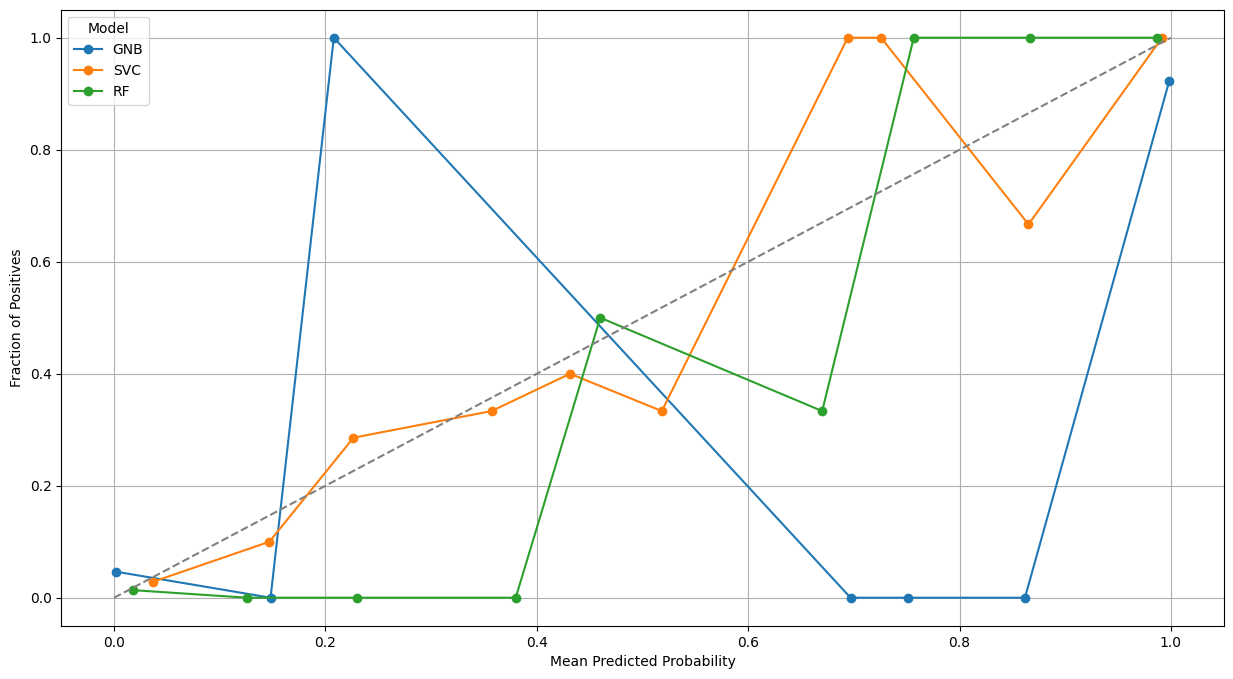

In [32]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    'GNB': GaussianNB(),
    'SVC': SVC(probability=True),
    'RF': RandomForestClassifier(n_estimators=100)
}

plt.figure(figsize=(15, 8))

for name, model in classifiers.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]

    true_prob, pred_prob = calibration_curve(
        y_test, prob, n_bins=10
    )

    plt.plot(pred_prob, true_prob, marker='o', label=name)

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend(title='Model')
plt.grid()
plt.show()

<Figure size 1500x400 with 0 Axes>

Text(0.5, 0, 'Mean predicted value')

Text(0, 0.5, 'Count')

Text(0.5, 0, 'Mean predicted value')

Text(0, 0.5, 'Count')

Text(0.5, 0, 'Mean predicted value')

Text(0, 0.5, 'Count')

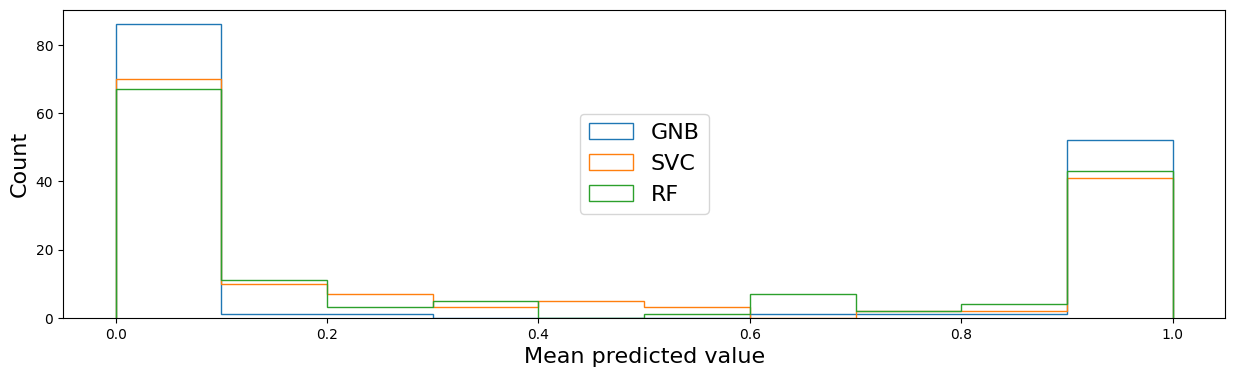

In [33]:
plt.figure(figsize=(15,4))
for name, classifier in classifiers.items():
    y_proba = classifier.fit(X_train, y_train).predict_proba(X_test)
    ax = plt.hist(y_proba[:,1], range=(0, 1), bins=10, label=name, histtype="step", lw=2)
    plt.xlabel("Mean predicted value", fontsize=16); plt.ylabel("Count",fontsize=16)
    plt.legend(fontsize=16, loc='center' )

<Figure size 1000x1000 with 0 Axes>

GaussianNB()

(array([86.,  1.,  1.,  0.,  0.,  0.,  1.,  1.,  1., 52.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 [<matplotlib.patches.Polygon at 0x7856e57f25d0>])

SVC(probability=True)

(array([70., 10.,  7.,  3.,  5.,  3.,  0.,  2.,  2., 41.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 [<matplotlib.patches.Polygon at 0x7856e57f2850>])

RandomForestClassifier()

... (2 outputs left out)

(-0.05, 1.05)

Text(0.5, 1.0, 'Calibration plots  (reliability curve)')

Text(0.5, 0, 'Mean predicted value')

Text(0, 0.5, 'Count')

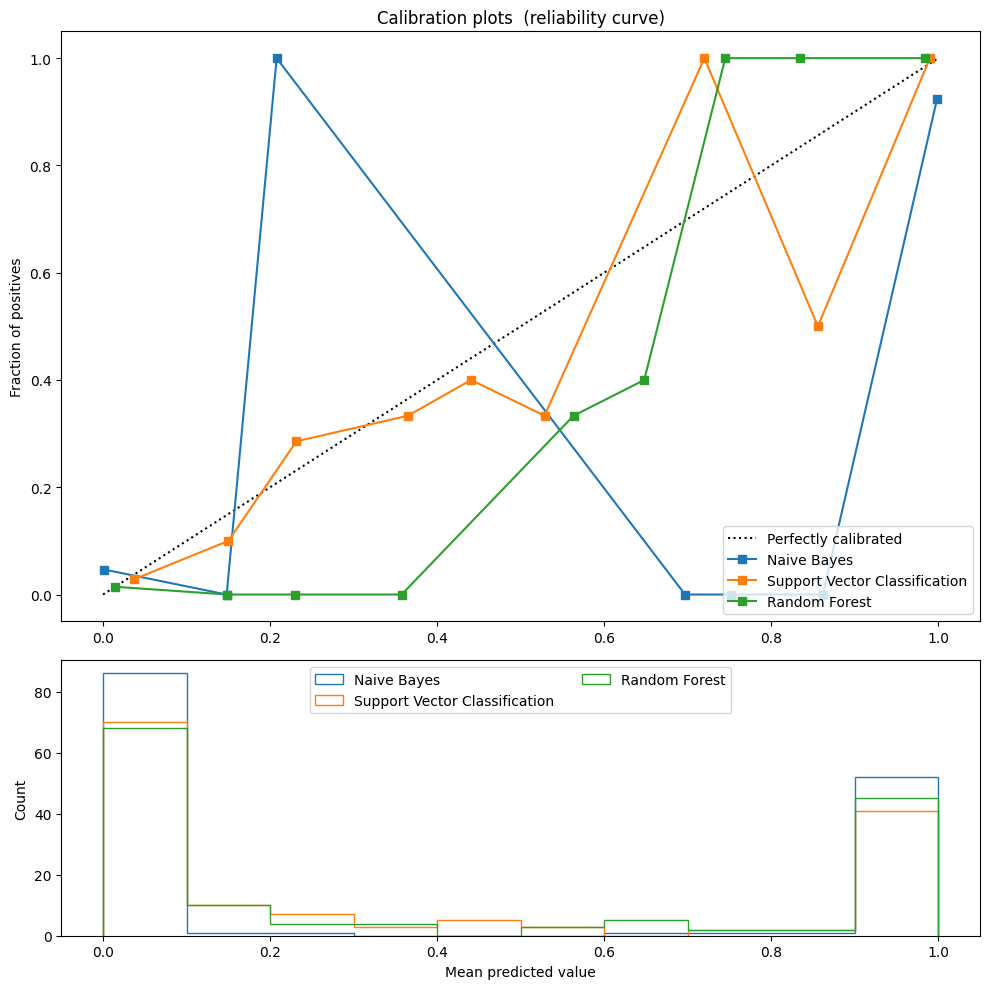

In [35]:
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

# Create classifiers
lr = LogisticRegression()
gnb = GaussianNB()
svc = SVC(probability=True)
rfc = RandomForestClassifier()


# #############################################################################
# Plot calibration plots

plt.figure(figsize=(10, 10))
ax1 = plt.subplot2grid((3, 1), (0, 0), rowspan=2)
ax2 = plt.subplot2grid((3, 1), (2, 0))

ax1.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")
for clf, name in [#(lr, 'Logistic'),
                  (gnb, 'Naive Bayes'),
                  (svc, 'Support Vector Classification'),
                  (rfc, 'Random Forest')]:
    clf.fit(X_train, y_train)
    if hasattr(clf, "predict_proba"):
        prob_pos = clf.predict_proba(X_test)[:, 1]
    else:  # use decision function
        prob_pos = clf.decision_function(X_test)
        prob_pos = \
            (prob_pos - prob_pos.min()) / (prob_pos.max() - prob_pos.min())
    fraction_of_positives, mean_predicted_value = \
        calibration_curve(y_test, prob_pos, n_bins=10)

    ax1.plot(mean_predicted_value, fraction_of_positives, "s-",
             label="%s" % (name, ))

    ax2.hist(prob_pos, range=(0, 1), bins=10, label=name,
             histtype="step", lw=2)

ax1.set_ylabel("Fraction of positives")
ax1.set_ylim([-0.05, 1.05])
ax1.legend(loc="lower right")
ax1.set_title('Calibration plots  (reliability curve)')

ax2.set_xlabel("Mean predicted value")
ax2.set_ylabel("Count")
ax2.legend(loc="upper center", ncol=2)

plt.tight_layout()
plt.show()

Naive Bayes:
	Brier: 0.071
	Precision: 0.873
	Recall: 0.906
	F1: 0.889

Naive Bayes + Isotonic:
	Brier: 0.057
	Precision: 0.810
	Recall: 0.962
	F1: 0.879

Naive Bayes + Sigmoid:
	Brier: 0.066
	Precision: 0.873
	Recall: 0.906
	F1: 0.889

SVC:
	Brier: 0.054
	Precision: 0.978
	Recall: 0.830
	F1: 0.898

SVC + Isotonic:
	Brier: 0.057
	Precision: 0.887
	Recall: 0.887
	F1: 0.887

SVC + Sigmoid:
	Brier: 0.056
	Precision: 0.957
	Recall: 0.849
	F1: 0.900



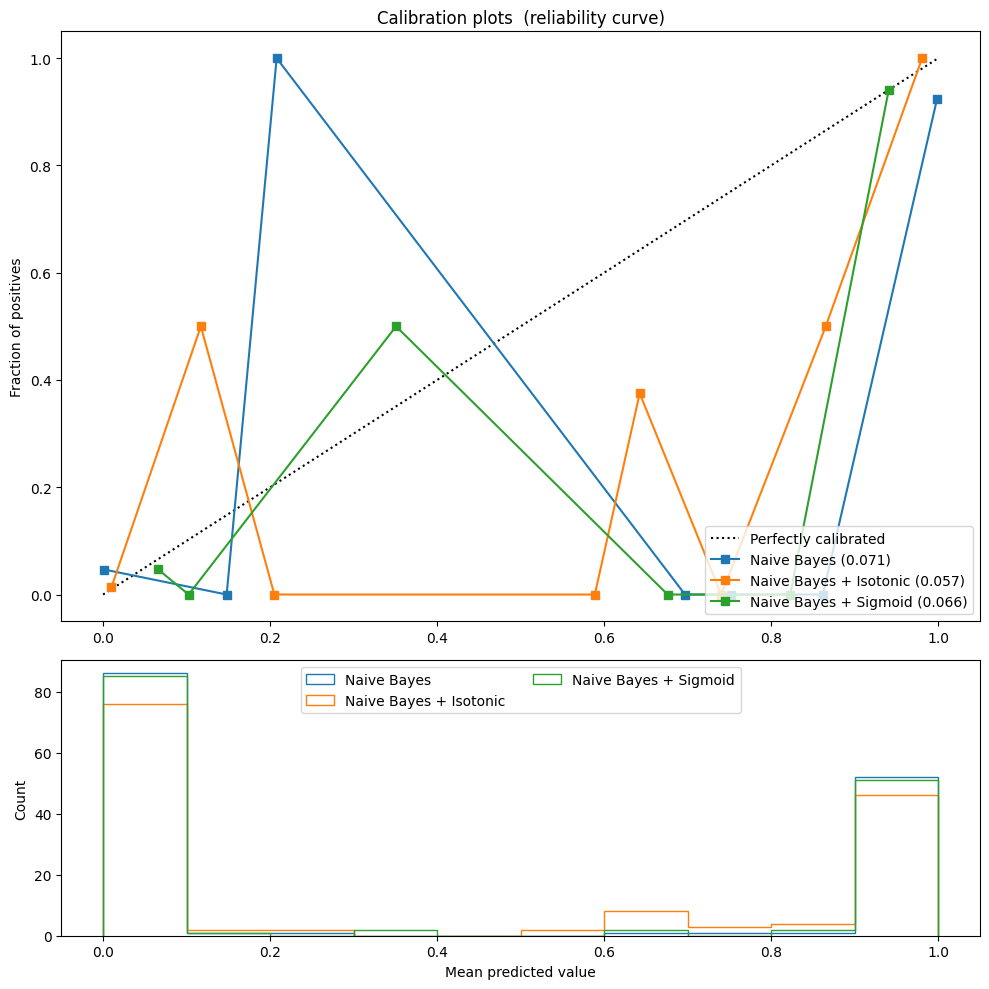

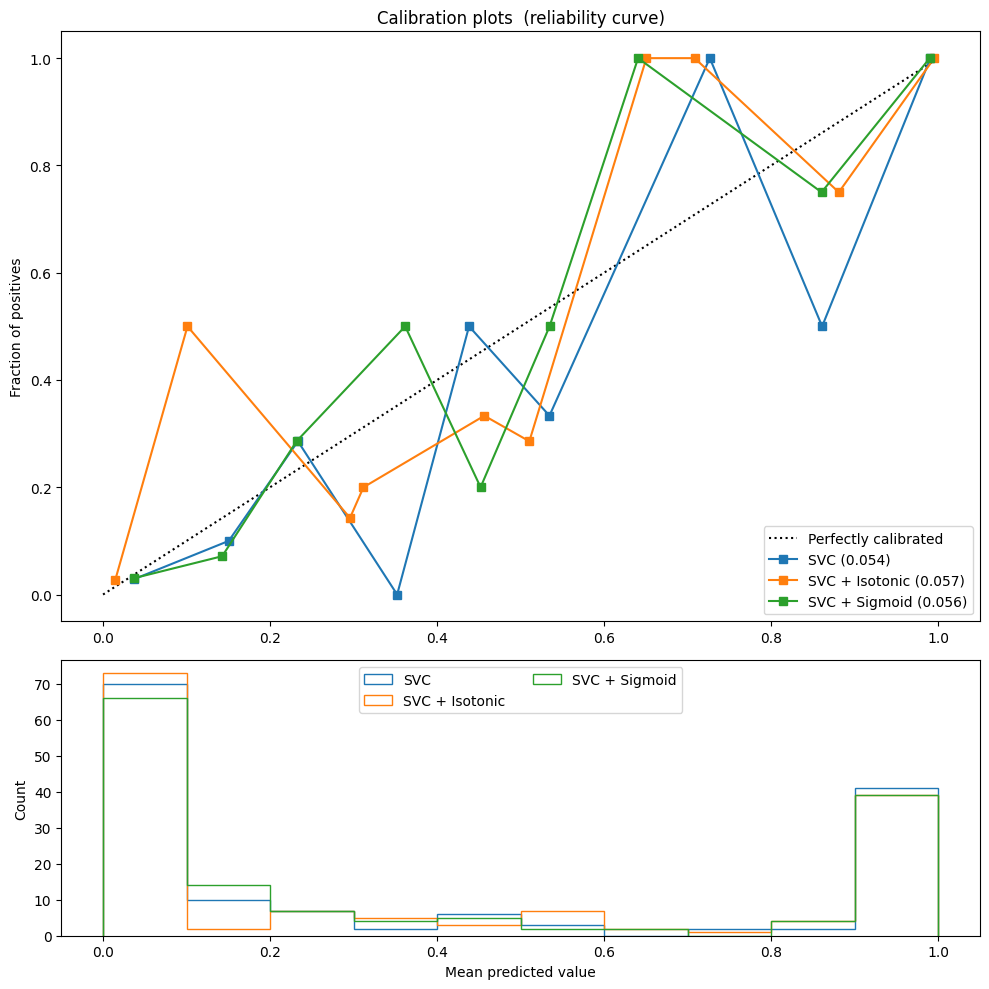

In [36]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (brier_score_loss, precision_score, recall_score, f1_score)
def plot_calibration_curve(est, name, fig_index):
    """Plot calibration curve for est w/o and with calibration. """
    # Calibrated with isotonic calibration
    isotonic = CalibratedClassifierCV(est, cv=2, method='isotonic')

    # Calibrated with sigmoid calibration
    sigmoid = CalibratedClassifierCV(est, cv=2, method='sigmoid')

    # Logistic regression with no calibration as baseline
    lr = LogisticRegression(C=1.)

    fig = plt.figure(fig_index, figsize=(10, 10))
    ax1 = plt.subplot2grid((3, 1), (0, 0), rowspan=2)
    ax2 = plt.subplot2grid((3, 1), (2, 0))

    ax1.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")
    for clf, name in [#(lr, 'Logistic'),
                      (est, name),
                      (isotonic, name + ' + Isotonic'),
                      (sigmoid, name + ' + Sigmoid')]:
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        if hasattr(clf, "predict_proba"):
            prob_pos = clf.predict_proba(X_test)[:, 1]
        else:  # use decision function
            prob_pos = clf.decision_function(X_test)
            prob_pos = \
                (prob_pos - prob_pos.min()) / (prob_pos.max() - prob_pos.min())

        clf_score = brier_score_loss(y_test, prob_pos, pos_label=y.max())
        print("%s:" % name)
        print("\tBrier: %1.3f" % (clf_score))
        print("\tPrecision: %1.3f" % precision_score(y_test, y_pred))
        print("\tRecall: %1.3f" % recall_score(y_test, y_pred))
        print("\tF1: %1.3f\n" % f1_score(y_test, y_pred))

        fraction_of_positives, mean_predicted_value = \
            calibration_curve(y_test, prob_pos, n_bins=10)

        ax1.plot(mean_predicted_value, fraction_of_positives, "s-",
                 label="%s (%1.3f)" % (name, clf_score))

        ax2.hist(prob_pos, range=(0, 1), bins=10, label=name,
                 histtype="step", lw=2)

    ax1.set_ylabel("Fraction of positives")
    ax1.set_ylim([-0.05, 1.05])
    ax1.legend(loc="lower right")
    ax1.set_title('Calibration plots  (reliability curve)')

    ax2.set_xlabel("Mean predicted value")
    ax2.set_ylabel("Count")
    ax2.legend(loc="upper center", ncol=2)

    plt.tight_layout()

# Plot calibration curve for Gaussian Naive Bayes
plot_calibration_curve(GaussianNB(), "Naive Bayes", 1)

# Plot calibration curve for Linear SVC
plot_calibration_curve(SVC(probability=True), "SVC", 2)

plt.show()

### 실습 breast_cancer

In [37]:
# Import the dataset Wisconsin breast cancer dataset from skelarn.
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
cancer.keys()

# Create a DataFrame.
cancer = pd.DataFrame(np.c_[cancer['target'], cancer['data']],
                      columns = np.append('target', cancer['feature_names']))

# Assign the label 0 to benign samples and 1 to malignant samples
# change the datatype of target from float to integer.
cancer['target'] = cancer['target'].map({0.0: 1, 1.0:0}).astype('int64')
# Check the structure of the dataset
cancer

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

,target,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [38]:
cancer['target'].value_counts(normalize=True)

,proportion
target,
0,0.627417
1,0.372583


In [39]:
# Separate the independent variables from the dependent variable.
X = cancer.drop('target', axis = 1)
y = cancer['target']
# Divide the dataset into train (80%) and test (20%).
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

SVC(probability=True, random_state=0)

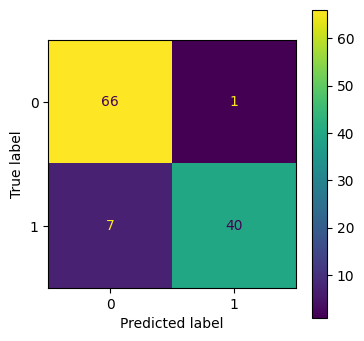

In [40]:
from sklearn.svm import SVC
clf = SVC(random_state=0, probability=True)
clf.fit(X_train, y_train)

# plot_confusion_matrix 대신 ConfusionMatrixDisplay.from_estimator를 사용합니다.
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test)
plt.show()

array([[66,  1],
       [ 7, 40]])

<Axes: >

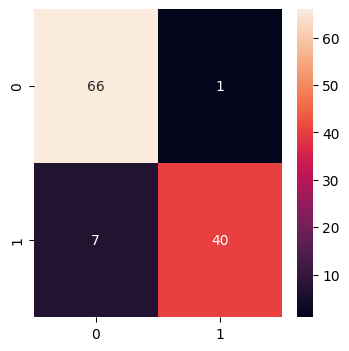

In [41]:
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X_test)
confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True)

In [42]:
from sklearn.metrics import classification_report
target_names = ['Negative(0)', 'Positive(1)']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

 Negative(0)       0.90      0.99      0.94        67
 Positive(1)       0.98      0.85      0.91        47

    accuracy                           0.93       114
   macro avg       0.94      0.92      0.93       114
weighted avg       0.93      0.93      0.93       114



In [43]:
from sklearn.metrics import classification_report
y_pred = clf.predict(X_test)
target_names = ['Negative(0)', 'Positive(1)']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

 Negative(0)       0.90      0.99      0.94        67
 Positive(1)       0.98      0.85      0.91        47

    accuracy                           0.93       114
   macro avg       0.94      0.92      0.93       114
weighted avg       0.93      0.93      0.93       114



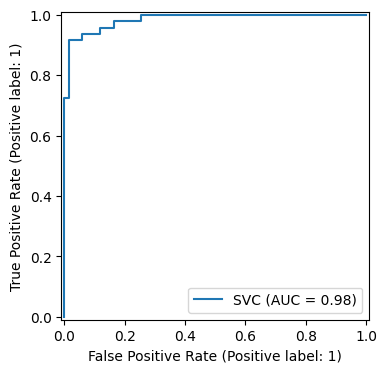

In [44]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.show()

In [45]:
# 0일 확률, 1일 확률
clf.predict_proba(X_test)

array([[4.47190021e-01, 5.52809979e-01],
       [9.32056319e-01, 6.79436813e-02],
       [9.06245895e-01, 9.37541050e-02],
       [6.26383128e-01, 3.73616872e-01],
       [9.71464229e-01, 2.85357711e-02],
       [9.65569742e-01, 3.44302584e-02],
       [9.73985585e-01, 2.60144153e-02],
       [9.70308447e-01, 2.96915528e-02],
       [9.55855313e-01, 4.41446874e-02],
       [9.76665840e-01, 2.33341602e-02],
       [6.68061451e-01, 3.31938549e-01],
       [6.99722136e-01, 3.00277864e-01],
       [9.73952199e-01, 2.60478011e-02],
       [1.14557359e-01, 8.85442641e-01],
       [6.90059522e-01, 3.09940478e-01],
       [2.88773708e-02, 9.71122629e-01],
       [9.68514766e-01, 3.14852341e-02],
       [1.78786592e-07, 9.99999821e-01],
       [5.02048260e-03, 9.94979517e-01],
       [2.45950428e-07, 9.99999754e-01],
       [1.96470240e-01, 8.03529760e-01],
       [9.92370856e-02, 9.00762914e-01],
       [9.13800043e-01, 8.61999569e-02],
       [9.49010708e-01, 5.09892923e-02],
       [5.386627

In [46]:
clf.predict_proba(X_test).sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [47]:
y_test

,target
512,1
457,0
439,0
298,0
37,0
...,...
213,1
519,0
432,1
516,1


In [48]:
((clf.predict_proba(X_test)[:,1] >= 0.5) == y_test).mean()

np.float64(0.9385964912280702)

In [49]:
from sklearn.metrics import roc_auc_score
y_score = clf.predict_proba(X_test)[:, 1]

roc_auc_score(y_test, y_score)

np.float64(0.9844395046046364)

In [50]:
from sklearn.metrics import average_precision_score
average_precision = average_precision_score(y_test, y_score)
print('Average precision-recall score: {0:0.2f}'.format(average_precision))

Average precision-recall score: 0.98


Text(0.5, 1.0, '2-class Precision-Recall curve: AP=0.98')

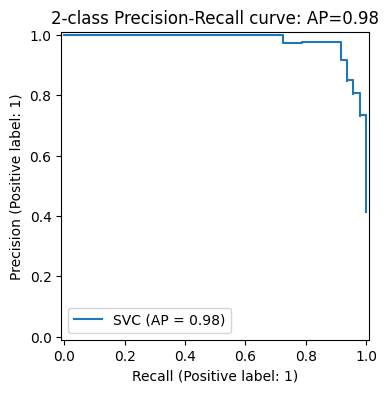

In [51]:
from sklearn.metrics import PrecisionRecallDisplay

disp = PrecisionRecallDisplay.from_estimator(clf, X_test, y_test)
disp.ax_.set_title('2-class Precision-Recall curve: AP={0:0.2f}'.format(average_precision))
plt.show()

In [52]:
from sklearn.metrics import brier_score_loss
# 현재 데이터셋(114개 샘플)에 맞게 y_score를 새로 업데이트합니다.
y_score = clf.predict_proba(X_test)[:, 1]
brier_score_loss(y_test, y_score)

np.float64(0.04665283092042539)

In [53]:
y_probas = clf.predict_proba(X_test)

In [54]:
from sklearn.metrics import log_loss
log_loss(y_test, y_probas)


0.1636372395650422

In [55]:
from sklearn.metrics import matthews_corrcoef
matthews_corrcoef(y_test, y_pred)


np.float64(0.8576521296725972)

In [56]:
from sklearn.metrics import cohen_kappa_score
cohen_kappa_score(y_test, y_pred)

np.float64(0.8523794108125606)

# End